# RIN - Experiment 6b: retention-law benchmark on a richer golden-world

This notebook builds a larger readable benchmark graph, draws it if `networkx` + `matplotlib` are available, and compares several local retention laws.

The benchmark is intentionally synthetic. The goal is not to prove a law of memory from one tiny world, but to discriminate mechanism families before moving to more expensive experiments.


In [1]:
import sys
from pathlib import Path

def find_repo_root(marker="requirements.txt"):
    path = Path.cwd()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find repo root (looked for {marker})")

REPO_ROOT = find_repo_root()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))


In [2]:
%load_ext autoreload
%autoreload 2


## Graph definition

The graph has four readable regions:

- Home / return episodes
- Travel / check-in
- Work / equipment
- Coffee / health

Event nodes are explicit so that the intended answer is licensed by the graph structure, not by outside common sense.


In [3]:
from collections import defaultdict
from itertools import product

import numpy as np

from embryonic.numberbatch import Numberbatch
from embryonic.query import longest_match_terms, query_vectors
from memory.edge import Edge
from memory.graph import MemoryGraph
from memory.node import Node
from memory.retrieval import nearest_nodes_by_embedding
from memory.similarity import cosine_similarity

NUMBERBATCH_FILE = REPO_ROOT / "source" / "numberbatch-en-19.08.txt.gz"

NODE_SPECS = [
    ("apartment", "/c/en/apartment", "concept", 0.7, 2.5, "home"),
    ("home life", "/c/en/home_life", "concept", 0.7, 2.5, "home"),
    ("elevator", "/c/en/elevator", "concept", 0.7, 1.5, "home"),
    ("door", "/c/en/door", "concept", 0.7, 1.2, "home"),
    ("wallet", "/c/en/wallet", "concept", 0.7, 1.0, "home"),
    ("keys", "/c/en/key", "concept", 0.7, 1.0, "home"),
    ("cats", "/c/en/cat", "concept", 0.7, 1.5, "home"),
    ("cat food", "/c/en/cat_food", "concept", 0.7, 1.0, "home"),
    ("elevator turnaround", None, "episode", 0.8, 1.5, "home"),
    ("feeding alarm", None, "episode", 0.8, 1.5, "home"),
    ("trip", "/c/en/trip", "concept", 0.7, 2.5, "travel"),
    ("travel planning", "/c/en/travel", "concept", 0.7, 2.5, "travel"),
    ("airport", "/c/en/airport", "concept", 0.7, 1.5, "travel"),
    ("check in", "/c/en/check_in", "concept", 0.7, 1.5, "travel"),
    ("passport", "/c/en/passport", "concept", 0.7, 1.0, "travel"),
    ("boarding pass", "/c/en/boarding_pass", "concept", 0.7, 1.0, "travel"),
    ("suitcase", "/c/en/suitcase", "concept", 0.7, 1.5, "travel"),
    ("hotel", "/c/en/hotel", "concept", 0.7, 1.5, "travel"),
    ("azores", "/c/en/azores", "concept", 0.7, 1.2, "travel"),
    ("work setup", "/c/en/work", "concept", 0.7, 2.5, "work"),
    ("office", "/c/en/office", "concept", 0.7, 2.5, "work"),
    ("meeting", "/c/en/meeting", "concept", 0.7, 1.5, "work"),
    ("email", "/c/en/email", "concept", 0.7, 1.5, "work"),
    ("laptop", "/c/en/laptop", "concept", 0.7, 1.5, "work"),
    ("charger", "/c/en/charger", "concept", 0.7, 1.0, "work"),
    ("dead laptop", None, "episode", 0.8, 1.5, "work"),
    ("coffee", "/c/en/coffee", "concept", 0.7, 1.5, "health"),
    ("caffeine", "/c/en/caffeine", "concept", 0.7, 1.0, "health"),
    ("beverage", "/c/en/beverage", "concept", 0.7, 2.5, "health"),
    ("energy", "/c/en/energy", "concept", 0.7, 1.5, "health"),
    ("sleep loss", "/c/en/sleep_deprivation", "concept", 0.7, 1.5, "health"),
    ("water", "/c/en/water", "concept", 0.7, 1.5, "health"),
    ("headache", "/c/en/headache", "concept", 0.7, 1.2, "health"),
]

EDGE_SPECS = [
    ("apartment", "home life", 1.2),
    ("apartment", "door", 0.9),
    ("apartment", "wallet", 0.8),
    ("apartment", "keys", 0.8),
    ("apartment", "cats", 0.9),
    ("elevator", "door", 1.0),
    ("elevator", "elevator turnaround", 1.3),
    ("elevator turnaround", "wallet", 1.8),
    ("elevator turnaround", "keys", 1.8),
    ("elevator turnaround", "apartment", 0.4),
    ("elevator turnaround", "elevator", 1.1),
    ("cats", "cat food", 1.3),
    ("cats", "home life", 0.4),
    ("feeding alarm", "cats", 1.9),
    ("feeding alarm", "cat food", 1.7),
    ("feeding alarm", "apartment", 0.1),
    ("feeding alarm", "home life", 0.1),
    ("trip", "travel planning", 1.3),
    ("trip", "airport", 1.1),
    ("trip", "suitcase", 1.0),
    ("trip", "hotel", 0.9),
    ("trip", "azores", 1.0),
    ("airport", "check in", 1.3),
    ("check in", "passport", 1.8),
    ("check in", "boarding pass", 1.8),
    ("check in", "airport", 0.6),
    ("passport", "boarding pass", 0.5),
    ("azores", "hotel", 0.8),
    ("office", "work setup", 1.2),
    ("office", "meeting", 1.0),
    ("office", "email", 0.9),
    ("work setup", "laptop", 1.2),
    ("laptop", "charger", 1.3),
    ("dead laptop", "charger", 1.8),
    ("dead laptop", "laptop", 1.2),
    ("dead laptop", "office", 0.4),
    ("dead laptop", "work setup", 0.5),
    ("meeting", "email", 0.6),
    ("coffee", "caffeine", 1.5),
    ("coffee", "beverage", 1.0),
    ("coffee", "energy", 1.2),
    ("coffee", "sleep loss", 0.8),
    ("beverage", "water", 1.2),
    ("beverage", "energy", 0.6),
    ("beverage", "headache", 0.4),
    ("water", "headache", 0.7),
    ("sleep loss", "headache", 0.9),
    ("office", "coffee", 0.5),
    ("trip", "coffee", 0.3),
    ("apartment", "trip", 0.2),
]

QUERY_SPECS = [
    ("Q1", "why coffee gives energy", ["caffeine"], ["beverage"]),
    ("Q2", "what matters at check in", ["passport", "boarding pass"], ["trip", "azores"]),
    ("Q3", "what helps after dead laptop", ["charger"], ["office", "work setup"]),
    ("Q4", "what caused the feeding alarm", ["cats", "cat food"], ["apartment", "home life"]),
    ("Q5", "what did the elevator turnaround mean", ["wallet", "keys"], ["apartment", "cats"]),
    ("Q6", "tell me about apartment life", ["apartment", "home life"], ["wallet", "cats"]),
    ("Q7", "tell me about travel planning", ["trip", "travel planning"], ["passport", "airport"]),
]

FORMULA_GRIDS = {
    "R0": [{}],
    "R1": [dict(beta=b, gamma=g) for b, g in product([0.1, 0.25, 0.5, 0.75, 1.0], [0.5, 0.75, 1.0, 1.25])],
    "R2": [dict(beta=b, gamma=g) for b, g in product([0.1, 0.25, 0.5, 0.75, 1.0], [0.5, 0.75, 1.0, 1.25])],
    "R3": [dict(alpha=a, beta=b, gamma=g) for a, b, g in product([0.5, 1.0, 1.5], [0.1, 0.25, 0.5, 0.75, 1.0], [0.5, 0.75, 1.0, 1.25])],
    "R4": [dict(beta=b, gamma=g) for b, g in product([0.1, 0.25, 0.5, 0.75, 1.0], [0.5, 0.75, 1.0, 1.25])],
    "R5": [dict(alpha=a, beta=b, gamma=g) for a, b, g in product([0.5, 1.0, 1.5], [0.1, 0.25, 0.5, 0.75, 1.0], [0.5, 0.75, 1.0, 1.25])],
}

POSITIONS = {
    "apartment": (-5.0, 2.0), "home life": (-4.0, 3.0), "elevator": (-6.0, 0.5), "door": (-5.3, 0.7),
    "wallet": (-4.1, 1.1), "keys": (-3.8, 0.3), "cats": (-4.2, 1.9), "cat food": (-3.2, 1.8),
    "elevator turnaround": (-6.2, 1.6), "feeding alarm": (-5.1, 3.3),
    "trip": (0.0, 5.0), "travel planning": (1.2, 5.8), "airport": (-0.7, 4.0), "check in": (0.2, 3.7),
    "passport": (0.9, 2.8), "boarding pass": (-0.1, 2.7), "suitcase": (-1.5, 5.4), "hotel": (1.7, 4.7),
    "azores": (2.0, 5.4),
    "work setup": (5.0, 2.5), "office": (5.8, 3.4), "meeting": (6.9, 3.0), "email": (6.8, 2.0),
    "laptop": (5.0, 1.3), "charger": (4.0, 0.8), "dead laptop": (4.3, 2.2),
    "coffee": (0.0, -1.2), "caffeine": (-1.0, -2.0), "beverage": (1.2, -2.0), "energy": (-0.4, -3.0),
    "sleep loss": (0.9, -3.2), "water": (2.3, -2.7), "headache": (1.7, -4.0),
}

CLUSTER_COLORS = {
    "home": "#d8b46a",
    "travel": "#6bb8c9",
    "work": "#98c27a",
    "health": "#d9857b",
}

NODE_CAPACITY = {name: cap for name, _uri, _kind, _conf, cap, _cluster in NODE_SPECS}
NODE_CLUSTER = {name: cluster for name, _uri, _kind, _conf, _cap, cluster in NODE_SPECS}

numberbatch = Numberbatch()
numberbatch.load(str(NUMBERBATCH_FILE))
print(f"loaded {len(numberbatch.terms):,} terms")

def phrase_embedding(text):
    uris = longest_match_terms(text, numberbatch)
    vecs = [numberbatch.vector_for(uri) for uri in uris if numberbatch.vector_for(uri) is not None]
    if not vecs:
        return None
    return np.mean(np.stack(vecs).astype(np.float32), axis=0)


def build_graph():
    G = MemoryGraph()
    content_to_id = {}
    for i, (content, uri, kind, conf, capacity, _cluster) in enumerate(NODE_SPECS):
        vector = numberbatch.vector_for(uri) if uri is not None else phrase_embedding(content)
        G.add_node(Node(id=i, content=content, embedding=vector, node_kind=kind, confidence=conf, provenance=[uri or content]))
        content_to_id[content] = i
    for src, dst, weight in EDGE_SPECS:
        G.add_edge(Edge(src=content_to_id[src], dst=content_to_id[dst], type="RelatedTo", weight=weight))
        G.add_edge(Edge(src=content_to_id[dst], dst=content_to_id[src], type="RelatedTo", weight=weight))
    return G, content_to_id

G, content_to_id = build_graph()
print(f"nodes: {len(G.nodes)}")
print(f"undirected motifs: {len(EDGE_SPECS)}")


loaded 516,782 terms
nodes: 33
undirected motifs: 50


## Optional graph picture

This cell is intentionally optional. If the current Python environment does not have `networkx` and `matplotlib`, it prints a message and the benchmark still runs.


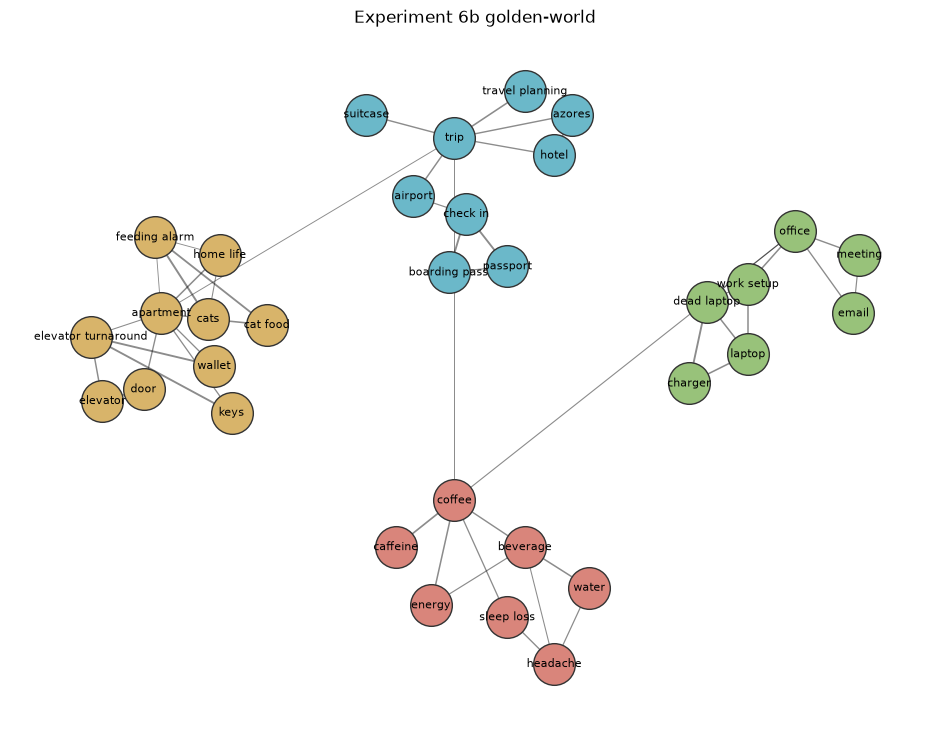

In [4]:
try:
    import matplotlib.pyplot as plt
    import networkx as nx

    H = nx.Graph()
    for name, _uri, _kind, _conf, _capacity, cluster in NODE_SPECS:
        H.add_node(name, cluster=cluster)
    for src, dst, weight in EDGE_SPECS:
        H.add_edge(src, dst, weight=weight)

    fig, ax = plt.subplots(figsize=(12, 9))
    for cluster, color in CLUSTER_COLORS.items():
        members = [name for name, _uri, _kind, _conf, _capacity, c in NODE_SPECS if c == cluster]
        nx.draw_networkx_nodes(H, POSITIONS, nodelist=members, node_color=color, node_size=900, linewidths=1.0, edgecolors="#333333", ax=ax)
    widths = [0.6 + 0.8 * data["weight"] / 1.9 for _u, _v, data in H.edges(data=True)]
    nx.draw_networkx_edges(H, POSITIONS, width=widths, alpha=0.45, ax=ax)
    nx.draw_networkx_labels(H, POSITIONS, font_size=8, ax=ax)
    ax.set_title("Experiment 6b golden-world")
    ax.axis("off")
    plt.show()
except ModuleNotFoundError as exc:
    print("graph drawing skipped:", exc)


## Query anchors

Before fitting anything, inspect what each query actually anchors on.


In [5]:
def anchors_for_query(G, query_text, top_k=2):
    qvecs = query_vectors(query_text, numberbatch)
    anchors = set()
    for qv in qvecs:
        anchors.update(nearest_nodes_by_embedding(G, qv, top_k=top_k))
    return qvecs, anchors

for qid, query_text, correct, distractors in QUERY_SPECS:
    vecs, anchors = anchors_for_query(G, query_text, top_k=2)
    print(qid, query_text)
    print("  matched terms:", longest_match_terms(query_text, numberbatch))
    print("  anchors:", [G.nodes[a].content for a in sorted(anchors)])
    print()


Q1 why coffee gives energy
  matched terms: ['/c/en/coffee', '/c/en/gives', '/c/en/energy']
  anchors: ['coffee', 'caffeine', 'energy']

Q2 what matters at check in
  matched terms: ['/c/en/matters', '/c/en/check_in']
  anchors: ['check in', 'boarding pass']

Q3 what helps after dead laptop
  matched terms: ['/c/en/helps', '/c/en/after', '/c/en/dead', '/c/en/laptop']
  anchors: ['laptop', 'dead laptop']

Q4 what caused the feeding alarm
  matched terms: ['/c/en/caused', '/c/en/feeding', '/c/en/alarm']
  anchors: ['feeding alarm']

Q5 what did the elevator turnaround mean
  matched terms: ['/c/en/elevator', '/c/en/turnaround', '/c/en/mean']
  anchors: ['elevator', 'elevator turnaround']

Q6 tell me about apartment life
  matched terms: ['/c/en/apartment', '/c/en/life']
  anchors: ['apartment', 'hotel']

Q7 tell me about travel planning
  matched terms: ['/c/en/travel', '/c/en/planning']
  anchors: ['trip', 'travel planning']



## Retention-law helpers

`incoming(B)` is transformed into retained local amplitude by dividing by a denominator law. The baseline `R0` uses denominator `1` everywhere.


In [6]:
def weighted_out_degree(G, node_id):
    return sum(edge.weight for edge in G.out_edges(node_id))


def relevance_function(G, query_vectors_):
    cache = {}

    def relevance(node_id):
        if node_id not in cache:
            node = G.nodes[node_id]
            if node.embedding is None:
                cache[node_id] = 1.0
            else:
                cache[node_id] = max(0.0, max(cosine_similarity(node.embedding, qv) for qv in query_vectors_))
        return cache[node_id]

    return relevance


def denominator_builder(formula_name, params):
    alpha = params.get("alpha", 1.0)
    beta = params.get("beta", 1.0)
    gamma = params.get("gamma", 1.0)

    def denominator(node_id):
        k_out = max(1, G.degree(node_id))
        s_out = max(1e-6, weighted_out_degree(G, node_id))
        capacity = NODE_CAPACITY[G.nodes[node_id].content]
        if formula_name == "R0":
            return 1.0
        if formula_name == "R1":
            return 1.0 + beta * (k_out ** gamma)
        if formula_name == "R2":
            return 1.0 + beta * (s_out ** gamma)
        if formula_name == "R3":
            return alpha + beta * (s_out ** gamma)
        if formula_name == "R4":
            return capacity + beta * (s_out ** gamma)
        if formula_name == "R5":
            return alpha + capacity + beta * (s_out ** gamma)
        raise KeyError(formula_name)

    return denominator


def diffuse_with_retention(G, source_amplitudes, query_vectors_, denominator, decay=0.8, floor_fraction=0.01, max_steps=20):
    floor = floor_fraction * max(source_amplitudes.values(), default=0.0)
    current = dict(source_amplitudes)
    peak = dict(current)
    relevance = relevance_function(G, query_vectors_)

    for _step in range(max_steps):
        active = {node_id: amount for node_id, amount in current.items() if amount >= floor}
        if not active:
            break

        incoming = defaultdict(float)
        for node_id, amount in active.items():
            out_edges = G.out_edges(node_id)
            gated_weights = [edge.weight * relevance(edge.dst) for edge in out_edges]
            total_weight = sum(gated_weights)
            if total_weight <= 0:
                continue
            for edge, gated_weight in zip(out_edges, gated_weights):
                incoming[edge.dst] += decay * amount * (gated_weight / total_weight)

        current = {dst: amount / max(1e-6, denominator(dst)) for dst, amount in incoming.items()}
        for node_id, amount in current.items():
            if amount > peak.get(node_id, 0.0):
                peak[node_id] = amount

    return peak


def evaluate_formula(formula_name, params, query_specs=None, top_k=2):
    active_queries = QUERY_SPECS if query_specs is None else query_specs
    solved = 0
    total_margin = 0.0
    rows = []

    for qid, query_text, correct_nodes, distractor_nodes in active_queries:
        qvecs, anchors = anchors_for_query(G, query_text, top_k=top_k)
        source = {anchor: 100.0 for anchor in anchors}
        peak = diffuse_with_retention(G, source, qvecs, denominator_builder(formula_name, params))
        best_correct = max(peak.get(content_to_id[name], 0.0) for name in correct_nodes)
        best_distractor = max(peak.get(content_to_id[name], 0.0) for name in distractor_nodes)
        success = best_correct > best_distractor
        solved += int(success)
        total_margin += best_correct - best_distractor
        rows.append({
            "id": qid,
            "query": query_text,
            "best_correct": best_correct,
            "best_distractor": best_distractor,
            "success": success,
            "anchors": [G.nodes[a].content for a in sorted(anchors)],
        })

    return solved, total_margin, rows


def select_best_parameters(formula_name, query_specs=None):
    best = None
    for params in FORMULA_GRIDS[formula_name]:
        solved, total_margin, rows = evaluate_formula(formula_name, params, query_specs=query_specs)
        candidate = (solved, total_margin, params, rows)
        if best is None or candidate[:2] > best[:2]:
            best = candidate
    return best


def print_rows(rows):
    for row in rows:
        print(f"{row['id']}  correct={row['best_correct']:.2f}  distractor={row['best_distractor']:.2f}  success={row['success']}  anchors={row['anchors']}")


## Parameter landscapes

Before picking a winner, inspect whether each family has a real parameter landscape or is almost flat.


In [7]:
def parameter_names_for_formula(formula_name):
    names = []
    for key in ["alpha", "beta", "gamma"]:
        if any(key in params for params in FORMULA_GRIDS[formula_name]):
            names.append(key)
    return names


parameter_landscapes = {}
for formula_name, grid in FORMULA_GRIDS.items():
    records = []
    for params in grid:
        solved, total_margin, rows = evaluate_formula(formula_name, params)
        record = {
            "formula": formula_name,
            "solved": solved,
            "margin": total_margin,
            "params": dict(params),
        }
        for key in parameter_names_for_formula(formula_name):
            record[key] = params.get(key)
        records.append(record)
    parameter_landscapes[formula_name] = records

for formula_name, records in parameter_landscapes.items():
    print(formula_name, "parameter count:", len(records))
    best_records = sorted(records, key=lambda r: (r["solved"], r["margin"]), reverse=True)[:5]
    for record in best_records:
        print("  ", record["params"], "->", f"{record['solved']}/{len(QUERY_SPECS)}", f"margin={record['margin']:.2f}")
    print()


R0 parameter count: 1
   {} -> 6/7 margin=426.02

R1 parameter count: 20
   {'beta': 0.1, 'gamma': 1.25} -> 7/7 margin=433.87
   {'beta': 0.25, 'gamma': 1.25} -> 7/7 margin=431.62
   {'beta': 0.1, 'gamma': 1.0} -> 7/7 margin=431.23
   {'beta': 0.25, 'gamma': 1.0} -> 7/7 margin=429.77
   {'beta': 0.1, 'gamma': 0.75} -> 7/7 margin=428.77

R2 parameter count: 20
   {'beta': 0.1, 'gamma': 1.0} -> 7/7 margin=421.95
   {'beta': 0.1, 'gamma': 1.25} -> 7/7 margin=420.69
   {'beta': 0.25, 'gamma': 0.5} -> 7/7 margin=419.76
   {'beta': 0.25, 'gamma': 0.75} -> 7/7 margin=418.18
   {'beta': 0.25, 'gamma': 1.0} -> 7/7 margin=416.40

R3 parameter count: 60
   {'alpha': 0.5, 'beta': 0.1, 'gamma': 1.25} -> 7/7 margin=430.19
   {'alpha': 0.5, 'beta': 0.25, 'gamma': 0.75} -> 7/7 margin=425.57
   {'alpha': 0.5, 'beta': 0.25, 'gamma': 1.0} -> 7/7 margin=422.41
   {'alpha': 1.0, 'beta': 0.1, 'gamma': 1.0} -> 7/7 margin=421.95
   {'alpha': 1.0, 'beta': 0.1, 'gamma': 1.25} -> 7/7 margin=420.69

R4 parameter 

## Optional parameter plots

Each axis is a formula degree of freedom. If a family has three free parameters, the third is shown by color. If a family had four, the fourth would be mapped to point size; in the current benchmark there are at most three.

The text labels on highlighted points show `solved/margin`.


R0 has no free parameters: 6/7 margin=426.02


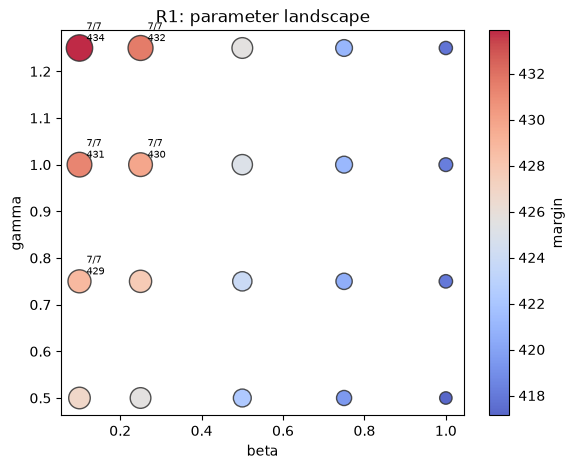

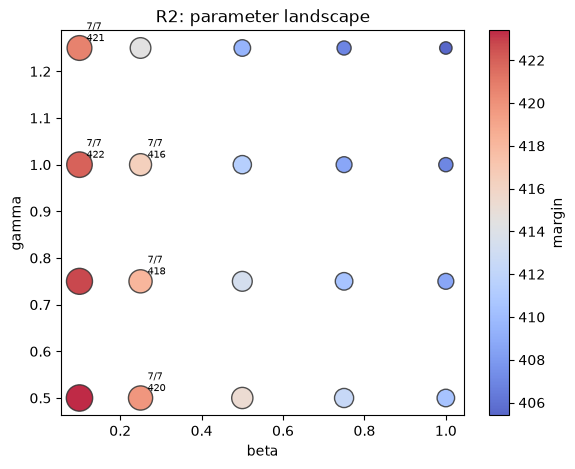

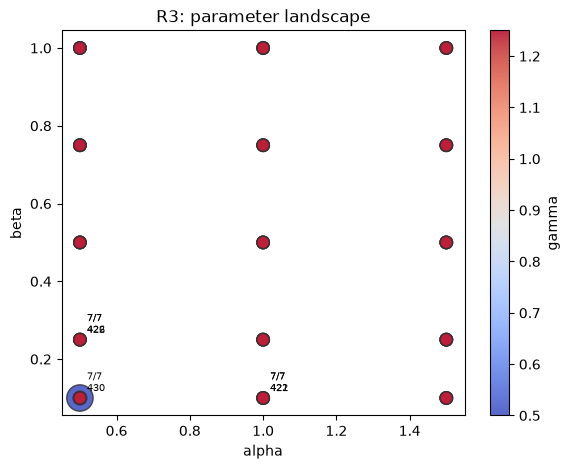

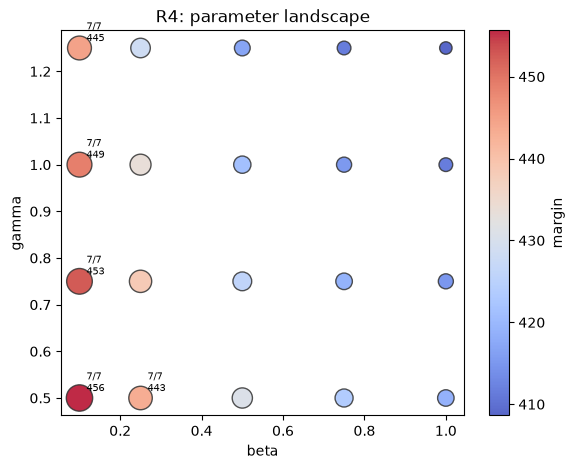

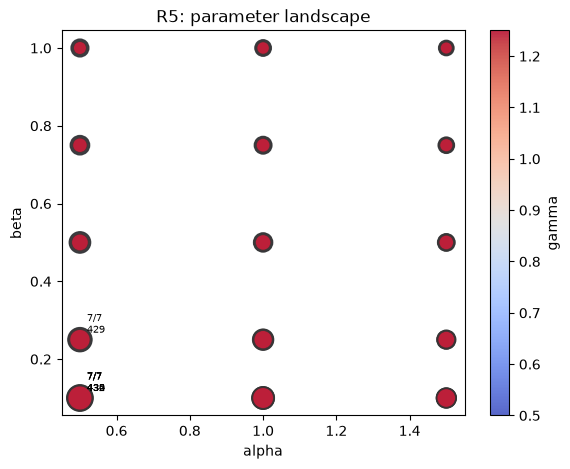

In [8]:
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    print("parameter plots skipped:", exc)
else:
    def scatter_sizes(records):
        margins = np.array([record["margin"] for record in records], dtype=np.float32)
        if len(margins) == 0 or float(margins.max() - margins.min()) < 1e-9:
            return np.full(len(records), 120.0)
        scaled = (margins - margins.min()) / (margins.max() - margins.min())
        return 80.0 + 280.0 * scaled


    def annotate_top_points(ax, records, xname, yname, top_n=5):
        top_records = sorted(records, key=lambda r: (r["solved"], r["margin"]), reverse=True)[:top_n]
        for record in top_records:
            label = f"{record['solved']}/{len(QUERY_SPECS)}\n{record['margin']:.0f}"
            ax.annotate(label, (record[xname], record[yname]), textcoords="offset points", xytext=(5, 5), fontsize=7)


    def plot_formula_landscape(formula_name):
        records = parameter_landscapes[formula_name]
        names = parameter_names_for_formula(formula_name)
        if not names:
            record = records[0]
            print(formula_name, "has no free parameters:", f"{record['solved']}/{len(QUERY_SPECS)}", f"margin={record['margin']:.2f}")
            return
        if len(names) == 1:
            xname = names[0]
            xs = [record[xname] for record in records]
            ys = [record["margin"] for record in records]
            colors = [record["solved"] for record in records]
            sizes = scatter_sizes(records)
            fig, ax = plt.subplots(figsize=(6, 4))
            scatter = ax.scatter(xs, ys, c=colors, s=sizes, cmap="coolwarm", alpha=0.85, edgecolors="#333333")
            ax.set_xlabel(xname)
            ax.set_ylabel("margin")
            ax.set_title(f"{formula_name}: 1D landscape")
            for record in sorted(records, key=lambda r: (r['solved'], r['margin']), reverse=True)[:5]:
                ax.annotate(f"{record['solved']}/{len(QUERY_SPECS)}", (record[xname], record['margin']), textcoords="offset points", xytext=(5, 5), fontsize=7)
            cbar = plt.colorbar(scatter, ax=ax)
            cbar.set_label("queries solved")
            plt.show()
            return

        xname, yname = names[0], names[1]
        xs = [record[xname] for record in records]
        ys = [record[yname] for record in records]
        sizes = scatter_sizes(records)
        if len(names) >= 3:
            colors = [record[names[2]] for record in records]
            color_label = names[2]
        else:
            colors = [record["margin"] for record in records]
            color_label = "margin"

        fig, ax = plt.subplots(figsize=(6.5, 5))
        scatter = ax.scatter(xs, ys, c=colors, s=sizes, cmap="coolwarm", alpha=0.85, edgecolors="#333333")
        annotate_top_points(ax, records, xname, yname, top_n=5)
        ax.set_xlabel(xname)
        ax.set_ylabel(yname)
        ax.set_title(f"{formula_name}: parameter landscape")
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label(color_label)
        plt.show()


    for formula_name in FORMULA_GRIDS:
        plot_formula_landscape(formula_name)


## In-sample best parameters per family


In [9]:
global_bests = {}
for formula_name in FORMULA_GRIDS:
    best = select_best_parameters(formula_name)
    global_bests[formula_name] = best
    solved, total_margin, params, rows = best
    print(formula_name, solved, round(total_margin, 2), params)
    print_rows(rows)
    print()


R0 6 426.02 {}
Q1  correct=100.00  distractor=30.93  success=True  anchors=['coffee', 'caffeine', 'energy']
Q2  correct=100.00  distractor=1.66  success=True  anchors=['check in', 'boarding pass']
Q3  correct=57.38  distractor=11.29  success=True  anchors=['laptop', 'dead laptop']
Q4  correct=40.43  distractor=9.58  success=True  anchors=['feeding alarm']
Q5  correct=3.95  distractor=6.03  success=False  anchors=['elevator', 'elevator turnaround']
Q6  correct=100.00  distractor=5.88  success=True  anchors=['apartment', 'hotel']
Q7  correct=100.00  distractor=10.35  success=True  anchors=['trip', 'travel planning']

R1 7 433.87 {'beta': 0.1, 'gamma': 1.25}
Q1  correct=100.00  distractor=19.75  success=True  anchors=['coffee', 'caffeine', 'energy']
Q2  correct=100.00  distractor=0.56  success=True  anchors=['check in', 'boarding pass']
Q3  correct=46.35  distractor=8.10  success=True  anchors=['laptop', 'dead laptop']
Q4  correct=32.66  distractor=6.87  success=True  anchors=['feeding al

## Leave-one-query-out validation


In [10]:
loo_summary = {}
for formula_name in FORMULA_GRIDS:
    held_out_solved = 0
    held_out_margin = 0.0
    chosen_params = []
    for i, held_out in enumerate(QUERY_SPECS):
        train_queries = QUERY_SPECS[:i] + QUERY_SPECS[i + 1 :]
        best_train = select_best_parameters(formula_name, query_specs=train_queries)
        chosen_params.append(best_train[2])
        solved, total_margin, rows = evaluate_formula(formula_name, best_train[2], query_specs=[held_out])
        held_out_solved += solved
        held_out_margin += total_margin
    loo_summary[formula_name] = {
        "solved": held_out_solved,
        "margin": held_out_margin,
        "params": chosen_params,
    }
    print(formula_name, held_out_solved, round(held_out_margin, 2))


R0 6 426.02
R1 7 408.11
R2 6 380.65
R3 6 349.93
R4 7 455.63
R5 7 435.4


## Winning family details

Inspect the strongest overall family on this benchmark.


In [11]:
winning_formula = max(loo_summary.items(), key=lambda item: (item[1]["solved"], item[1]["margin"]))[0]
winning_best = global_bests[winning_formula]
print("winning formula by held-out score:", winning_formula)
print("best global params:", winning_best[2])
print()
print_rows(winning_best[3])


winning formula by held-out score: R4
best global params: {'beta': 0.1, 'gamma': 0.5}

Q1  correct=100.00  distractor=11.55  success=True  anchors=['coffee', 'caffeine', 'energy']
Q2  correct=100.00  distractor=0.36  success=True  anchors=['check in', 'boarding pass']
Q3  correct=48.79  distractor=4.23  success=True  anchors=['laptop', 'dead laptop']
Q4  correct=34.46  distractor=3.64  success=True  anchors=['feeding alarm']
Q5  correct=3.40  distractor=1.61  success=True  anchors=['elevator', 'elevator turnaround']
Q6  correct=100.00  distractor=3.43  success=True  anchors=['apartment', 'hotel']
Q7  correct=100.00  distractor=6.19  success=True  anchors=['trip', 'travel planning']
